In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.12.8 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2175
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

assert X.shape == (4204, 57)
assert X_train.shape == (3153, 57) and X_test.shape == (1051, 57)
assert not data.isna().any().any()
assert set(np.unique(y)) == {0, 1}

(4204, 57) 39.9 (3153, 57) (1051, 57)


## Task 4: Random Forests & Ensembles

MOP 3231, Machine Learning (Python)

SEED = 2175 (last four digits of my student ID).

The positive class is spam. A false positive is a legitimate e-mail sent to spam, so the filter's target is at most 1% false positives. This is an old teaching dataset, so these results do not describe today's spam filters.

In [3]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

All comparisons use the same five training folds. I report accuracy unless another metric is named, and standard deviations use `ddof=0`. A paired difference is inside the fold spread when `abs(mean difference) <= std of differences`; in that case I do not name a winner. The test split reports results and does not choose thresholds, members or numbers of rounds.

In [4]:
import math
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_validate

def score_table(results):
    """Show five scores or paired differences, followed by their mean and std."""
    return pd.DataFrame(
        {name: list(values) + [values.mean(), values.std()] for name, values in results.items()},
        index=["fold 1", "fold 2", "fold 3", "fold 4", "fold 5", "mean", "std"],
    ).T

cv_scores = {}

### Part 1 · Bagging and out-of-bag estimates

In [5]:
def oob_mask(sample_indices, n_samples):
    """Return a Boolean mask of rows absent from a bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask

In [6]:
assert np.array_equal(oob_mask([0, 2, 2], 5), [False, True, False, True, True])
assert np.array_equal(oob_mask([], 3), [True, True, True])
indices = np.array([3, 0])
saved_indices = indices.copy()
mask = oob_mask(sample_indices=indices, n_samples=4)
assert np.array_equal(mask, [False, True, True, False])
assert mask.dtype == np.bool_ and mask.shape == (4,)
assert np.array_equal(indices, saved_indices)
assert oob_mask([], 0).shape == (0,)
print("oob_mask checks passed")

oob_mask checks passed


A bootstrap sample can contain the same row several times. I first count which rows each tree did not see, then let only those trees vote for a row. A tied vote goes to class 0.

In [7]:
bag.fit(X_train, y_train)
n_train = len(y_train)
oob_votes = np.zeros((n_train, 2), dtype=int)
oob_shares = []

for estimator, sample_indices, columns in zip(
        bag.estimators_, bag.estimators_samples_, bag.estimators_features_):
    mask = oob_mask(sample_indices, n_train)
    oob_shares.append(mask.mean())
    predictions = estimator.predict(X_train[mask][:, columns]).astype(int)
    oob_votes[np.flatnonzero(mask), predictions] += 1

expected_oob = (1 - 1 / n_train) ** n_train
display(pd.DataFrame({
    "observed": [np.mean(oob_shares), 1 - np.mean(oob_shares)],
    "formula": [expected_oob, 1 - expected_oob],
}, index=["out of bag", "in bag"]).round(6))

assert (oob_votes.sum(axis=1) > 0).all()
manual_oob = accuracy_score(y_train, oob_votes.argmax(axis=1))
print(f"manual OOB accuracy: {manual_oob:.6f}")
print(f"sklearn OOB accuracy: {bag.oob_score_:.6f}")
assert np.isclose(manual_oob, bag.oob_score_)

,observed,formula
out of bag,0.367507,0.367821
in bag,0.632493,0.632179


manual OOB accuracy: 0.936568
sklearn OOB accuracy: 0.936568


In [8]:
for name, model in {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}.items():
    cv_scores[name] = cross_validate(
        model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]

display(score_table(cv_scores).round(4))
part1_differences = {
    "bag - tree": cv_scores["bag"] - cv_scores["tree"],
    "rf - tree": cv_scores["rf"] - cv_scores["tree"],
    "bag_lr - lr": cv_scores["bag_lr"] - cv_scores["lr"],
}
display(score_table(part1_differences).round(4))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
tree,0.9002,0.8796,0.8859,0.8984,0.9032,0.8934,0.0091
bag,0.9334,0.9176,0.9160,0.9222,0.9476,0.9274,0.0118
rf,0.9414,0.9303,0.9319,0.9349,0.9460,0.9369,0.0059
lr,0.9445,0.9239,0.9303,0.9159,0.9397,0.9309,0.0104
bag_lr,0.9445,0.9271,0.9319,0.9175,0.9413,0.9324,0.0098


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
bag - tree,0.0333,0.0380,0.0301,0.0238,0.0444,0.0339,0.0070
rf - tree,0.0412,0.0507,0.0460,0.0365,0.0429,0.0434,0.0047
bag_lr - lr,0.0000,0.0032,0.0016,0.0016,0.0016,0.0016,0.0010


In [9]:
rf.fit(X_train, y_train)
rf_test_accuracy = rf.score(X_test, y_test)
rf_test_se = np.sqrt(rf_test_accuracy * (1 - rf_test_accuracy) / len(y_test))
rf_cv_mean = cv_scores["rf"].mean()
rf_cv_std = cv_scores["rf"].std()

print(f"forest OOB accuracy: {rf.oob_score_:.4f}")
print(f"forest CV accuracy: {rf_cv_mean:.4f} +/- {rf_cv_std:.4f}")
print(f"forest test accuracy: {rf_test_accuracy:.4f}; SE: {rf_test_se:.4f}")
print(f"absolute OOB-CV gap: {abs(rf.oob_score_ - rf_cv_mean):.4f}")
print("OOB and CV agree by the handout rule:", abs(rf.oob_score_ - rf_cv_mean) <= rf_cv_std)
print(f"OOB-test gap: {abs(rf.oob_score_ - rf_test_accuracy):.4f}")
print(f"CV-test gap: {abs(rf_cv_mean - rf_test_accuracy):.4f}")

forest OOB accuracy: 0.9445
forest CV accuracy: 0.9369 +/- 0.0059
forest test accuracy: 0.9572; SE: 0.0062
absolute OOB-CV gap: 0.0076
OOB and CV agree by the handout rule: False
OOB-test gap: 0.0127
CV-test gap: 0.0203


Reading the results:

- The mean OOB share is 0.367507 against the formula's 0.367821; the in-bag share is 0.632493 against 0.632179. Sampling 3,153 times does not give 3,153 different rows. My OOB accuracy is 0.936568, the same as scikit-learn's.
- Bagging improves the tree by 0.0339, with a paired std of 0.0070. The forest improves on the tree by 0.0434, with std 0.0047. Both gains are outside the paired spread. A deep tree changes a lot when its training rows change; averaging many such trees reduces that variance. Random feature choices also make forest trees less alike.
- Bagging logistic regression improves accuracy by only 0.0016, with paired std 0.0010. Under the handout's rule this is a small improvement outside the spread, rather than a tie. Logistic regression is already a stable learner, so bootstrap averaging has much less variance to remove than it does for a deep tree.
- Forest OOB accuracy is 0.9445, while CV gives 0.9369 with std 0.0059. Their gap of 0.0076 is larger than that std, so OOB is not a fair stand-in by the stated rule on this split. Test accuracy is higher, at 0.9572 with SE 0.0062; its gaps from OOB (0.0127) and CV (0.0203) are both larger than one test SE. The three estimates use different training/evaluation rows, and the test set appears easier here; I do not claim that the three numbers agree.

### Part 2 · Evaluating the filter: curves, a threshold, importances

The tree and forest are compared as probability models first. The operating threshold comes only from out-of-fold training probabilities. After that it stays fixed, even if the test false-positive rate is above 1%.

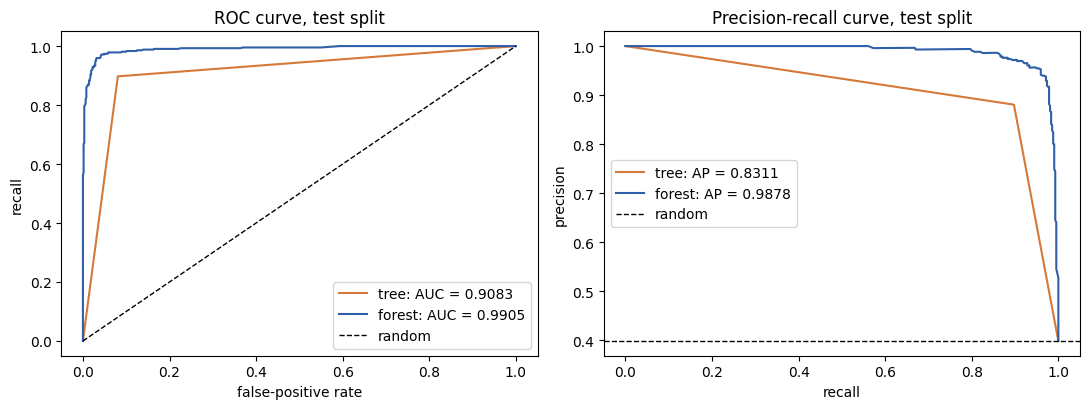

In [10]:
from sklearn.metrics import (
    average_precision_score, confusion_matrix, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import cross_val_predict

tree_fitted = clone(tree).fit(X_train, y_train)
tree_test_prob = tree_fitted.predict_proba(X_test)[:, 1]
rf_test_prob = rf.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, probabilities, color in [
        ("tree", tree_test_prob, "#d57838"), ("forest", rf_test_prob, "#2f5fa8")]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    axes[0].plot(fpr, tpr, color=color, label=f"{name}: AUC = {auc:.4f}")
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    axes[1].plot(recall, precision, color=color, label=f"{name}: AP = {ap:.4f}")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="random")
axes[0].set(xlabel="false-positive rate", ylabel="recall", title="ROC curve, test split")
axes[1].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label="random")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall curve, test split")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [11]:
rf_oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_fpr, oof_recall, thresholds = roc_curve(y_train, rf_oof, drop_intermediate=False)
allowed = np.flatnonzero(oof_fpr <= 0.01)
threshold_index = max(allowed, key=lambda i: (oof_recall[i], thresholds[i]))
threshold = thresholds[threshold_index]

print("threshold (unrounded):", float(threshold))
print(f"OOF FPR: {oof_fpr[threshold_index]:.6f}")
print(f"OOF recall: {oof_recall[threshold_index]:.6f}")
assert oof_fpr[threshold_index] <= 0.01
assert oof_recall[threshold_index] == oof_recall[allowed].max()
assert threshold == thresholds[allowed[oof_recall[allowed] == oof_recall[threshold_index]]].max()

threshold (unrounded): 0.7733333333333333
OOF FPR: 0.009494
OOF recall: 0.778839


In [12]:
filter_pred = (rf_test_prob >= threshold).astype(int)
filter_cm = confusion_matrix(y_test, filter_pred, labels=[0, 1])
tn, fp, fn, tp = filter_cm.ravel()
filter_precision = precision_score(y_test, filter_pred, zero_division=0)
filter_recall = recall_score(y_test, filter_pred)
filter_fpr = fp / (tn + fp)

display(pd.DataFrame(filter_cm,
    index=["true legitimate (0)", "true spam (1)"],
    columns=["keep (0)", "flag as spam (1)"]))
print(f"precision: {filter_precision:.4f}; recall: {filter_recall:.4f}; FPR: {filter_fpr:.4%}")
print(f"{fp} of {tn + fp} legitimate test e-mails were flagged as spam.")
print("The 1% target holds on the test split:", filter_fpr <= 0.01)

,keep (0),flag as spam (1)
true legitimate (0),630,2
true spam (1),92,327


precision: 0.9939; recall: 0.7804; FPR: 0.3165%
2 of 632 legitimate test e-mails were flagged as spam.
The 1% target holds on the test split: True


In [13]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")
importances = pd.DataFrame({
    "feature": feature_names,
    "permutation": perm.importances_mean,
    "impurity": rf.feature_importances_,
})
print("Top five by permutation importance (drop in test accuracy):")
display(importances.nlargest(5, "permutation")[["feature", "permutation"]].round(5))
print("Top five by impurity importance (share of training impurity decrease):")
display(importances.nlargest(5, "impurity")[["feature", "impurity"]].round(5))

Top five by permutation importance (drop in test accuracy):


,feature,permutation
6,word_freq_remove,0.02607
51,char_freq_exclam,0.01751
24,word_freq_hp,0.01656
55,capital_run_length_longest,0.00904
52,char_freq_dollar,0.00828


Top five by impurity importance (share of training impurity decrease):


,feature,impurity
51,char_freq_exclam,0.10979
52,char_freq_dollar,0.09192
6,word_freq_remove,0.07558
54,capital_run_length_average,0.07414
15,word_freq_free,0.07142


The forest ranks e-mails better than the single tree on both curves. A tree's probabilities are mostly 0 or 1, which leaves few operating points; averaging trees gives the forest a more detailed ranking.

The training-only threshold is 0.7733333333333333. Its OOF FPR is 0.9494% and recall is 0.7788. Keeping that exact threshold on test flags only 2 of 632 legitimate e-mails: FPR 0.3165%, below the 1% target. It catches 327 of 419 spam e-mails (recall 0.7804), with precision 0.9939; 92 spam e-mails are missed. Passing on this test split does not guarantee the same false-positive rate on future mail.

`word_freq_remove` ranks first by permutation importance (accuracy drop 0.02607) but third by impurity importance (0.07558). Permutation importance asks how much the fitted forest's test accuracy falls when a column is shuffled; impurity importance sums the training split improvements assigned to that column. Correlated features can share or replace each other's signal, and training impurity improvements need not translate to equally large test accuracy drops. The two values also have different units, so their sizes cannot be compared directly.

### Part 3 · Voting

In [14]:
def hard_vote(predictions, weights=None):
    """Sum votes in model order; ties go to the smallest class label."""
    labels = np.asarray(predictions)
    n_models, n_samples = labels.shape
    model_weights = np.ones(n_models) if weights is None else np.asarray(weights)
    counts = np.zeros((n_samples, int(labels.max(initial=0)) + 1))
    for model in range(n_models):
        counts[np.arange(n_samples), labels[model]] += model_weights[model]
    return counts.argmax(axis=1)

In [15]:
assert np.array_equal(hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]), [0, 1, 0])
assert np.array_equal(hard_vote([[0, 1], [1, 0]]), [0, 0])
assert np.array_equal(hard_vote([[0, 1], [1, 0]], weights=[1, 2]), [1, 0])
assert np.array_equal(hard_vote([[2, 0], [2, 1], [0, 1]]), [2, 1])
assert np.array_equal(hard_vote([[2, 5], [5, 2]], weights=[0, 0]), [0, 0])
assert np.array_equal(hard_vote([[0], [1]], weights=[1, 1 + 1e-12]), [1])
assert np.array_equal(hard_vote([[1], [1], [1], [0]], weights=[1e16, 1, 1, 1e16]), [0])
assert hard_vote(np.empty((3, 0), dtype=int)).shape == (0,)
vote_inputs = np.array([[2, 0], [0, 2]])
vote_weights = np.array([0.5, 1.5])
saved_inputs, saved_weights = vote_inputs.copy(), vote_weights.copy()
votes = hard_vote(predictions=vote_inputs, weights=vote_weights)
assert votes.shape == (2,) and np.issubdtype(votes.dtype, np.integer)
assert np.array_equal(vote_inputs, saved_inputs) and np.array_equal(vote_weights, saved_weights)
print("hard_vote checks passed")

hard_vote checks passed


Hard voting counts predicted labels; soft voting averages probabilities. Before comparing their accuracy, I check that my vote matches scikit-learn and measure how often the members disagree.

In [16]:
from itertools import combinations
from sklearn.ensemble import VotingClassifier

fitted_members = {name: clone(model).fit(X_train, y_train) for name, model in members}
member_predictions = np.stack([model.predict(X_test) for model in fitted_members.values()])
hard = VotingClassifier(members, voting="hard")
soft = VotingClassifier(members, voting="soft")
hard.fit(X_train, y_train)
manual_vote = hard_vote(member_predictions)
sklearn_vote = hard.predict(X_test)
agreement = np.mean(manual_vote == sklearn_vote)
print(f"agreement with sklearn hard voting: {agreement:.4%}")
assert np.array_equal(manual_vote, sklearn_vote)

member_names = [name for name, _ in members]
disagreement = []
for i, j in combinations(range(len(members)), 2):
    disagreement.append({
        "pair": f"{member_names[i]} / {member_names[j]}",
        "disagreement": np.mean(member_predictions[i] != member_predictions[j]),
    })
display(pd.DataFrame(disagreement).round(4))

agreement with sklearn hard voting: 100.0000%


,pair,disagreement
0,lr / knn,0.0590
1,lr / tree,0.0866
2,knn / tree,0.1113


In [17]:
for name, model in [("knn", knn), ("hard", hard), ("soft", soft)]:
    cv_scores[name] = cross_validate(
        model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]

display(score_table({name: cv_scores[name] for name in ["lr", "knn", "tree", "hard", "soft"]}).round(4))
best_member_name = max(member_names, key=lambda name: cv_scores[name].mean())
best_member = dict(members)[best_member_name]
print("best member by training CV:", best_member_name)
part3_differences = {
    "hard - best member": cv_scores["hard"] - cv_scores[best_member_name],
    "soft - best member": cv_scores["soft"] - cv_scores[best_member_name],
}
display(score_table(part3_differences).round(4))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
lr,0.9445,0.9239,0.9303,0.9159,0.9397,0.9309,0.0104
knn,0.9366,0.9239,0.9255,0.9111,0.9159,0.9226,0.0088
tree,0.9002,0.8796,0.8859,0.8984,0.9032,0.8934,0.0091
hard,0.9477,0.9287,0.9350,0.9238,0.9492,0.9369,0.0101
soft,0.9429,0.9255,0.9319,0.9286,0.9460,0.9350,0.0081


best member by training CV: lr


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
hard - best member,0.0032,0.0048,0.0048,0.0079,0.0095,0.0060,0.0023
soft - best member,-0.0016,0.0016,0.0016,0.0127,0.0063,0.0041,0.0050


My hard vote agrees with `VotingClassifier` on 100% of the test rows. The members disagree on 5.90% of rows for lr/knn, 8.66% for lr/tree and 11.13% for knn/tree, so their answers are not copies of each other.

Logistic regression is the best individual member by training CV mean (0.9309). Hard voting reaches 0.9369; its paired gain over lr is 0.0060 with std 0.0023. That gain is outside the spread, so hard voting beats the best member by the handout's rule. Soft voting reaches 0.9350, but its paired gain of 0.0041 is smaller than its std of 0.0050; these folds cannot separate soft voting from lr. Different member errors can help a majority vote, while averaging a deep tree's extreme probabilities does not automatically improve the result.

### Part 4 · Stacking

The meta-learner should see predictions for rows that each member did not train on. I build those out-of-fold columns by hand and check the result against scikit-learn. The naive comparison deliberately gives the meta-learner in-sample predictions instead.

In [18]:
from sklearn.ensemble import StackingClassifier

meta_train = np.column_stack([
    cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    for name, model in members
])
assert meta_train.shape == (len(y_train), 3)
meta = LogisticRegression().fit(meta_train, y_train)
meta_test = np.column_stack([
    fitted_members[name].predict_proba(X_test)[:, 1] for name, model in members
])
manual_stack_pred = meta.predict(meta_test)
stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
sklearn_stack_pred = stack.predict(X_test)

coef_gap = np.max(np.abs(meta.coef_ - stack.final_estimator_.coef_))
manual_stack_accuracy = accuracy_score(y_test, manual_stack_pred)
print(f"maximum absolute coefficient difference: {coef_gap:.12g}")
print("test predictions identical:", np.array_equal(manual_stack_pred, sklearn_stack_pred))
print(f"manual stacking test accuracy: {manual_stack_accuracy:.6f}")
print(f"sklearn stacking test accuracy: {stack.score(X_test, y_test):.6f}")
assert np.allclose(meta.coef_, stack.final_estimator_.coef_, rtol=1e-10, atol=1e-10)
assert np.array_equal(manual_stack_pred, sklearn_stack_pred)

maximum absolute coefficient difference: 0
test predictions identical: True
manual stacking test accuracy: 0.946717
sklearn stacking test accuracy: 0.946717


In [19]:
naive_train = np.column_stack([
    clone(model).fit(X_train, y_train).predict_proba(X_train)[:, 1]
    for name, model in members
])
naive_meta = LogisticRegression().fit(naive_train, y_train)
meta_coefficients = pd.DataFrame({
    "member": member_names,
    "naive coefficient": naive_meta.coef_[0],
    "OOF coefficient": meta.coef_[0],
})
display(meta_coefficients.round(4))

,member,naive coefficient,OOF coefficient
0,lr,1.9026,3.6111
1,knn,1.8293,3.1074
2,tree,8.3053,1.3444


In [20]:
cv_scores["stack"] = cross_validate(
    stack, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
display(score_table({name: cv_scores[name] for name in ["stack", "soft", best_member_name]}).round(4))
part4_differences = {
    "stack - best member": cv_scores["stack"] - cv_scores[best_member_name],
    "stack - soft": cv_scores["stack"] - cv_scores["soft"],
}
display(score_table(part4_differences).round(4))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
stack,0.9477,0.9334,0.9366,0.9254,0.9460,0.9378,0.0082
soft,0.9429,0.9255,0.9319,0.9286,0.9460,0.9350,0.0081
lr,0.9445,0.9239,0.9303,0.9159,0.9397,0.9309,0.0104


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
stack - best member,0.0032,0.0095,0.0063,0.0095,0.0063,0.0070,0.0024
stack - soft,0.0048,0.0079,0.0048,-0.0032,0.0000,0.0029,0.0039


The manual OOF stack matches scikit-learn exactly here: the largest coefficient difference is 0, predictions are identical, and both test accuracies are 0.946717.

The naive fit gives the tree a coefficient of 8.3053, compared with 1.3444 in the OOF fit. An unrestricted tree can memorise its own training labels, so its in-sample probability looks much more useful than it is on unseen rows. OOF predictions expose those errors, and the meta-learner relies more on logistic regression and KNN instead.

Stacking has mean CV accuracy 0.9378, against 0.9309 for the best member, lr. Their paired difference is 0.0070 with std 0.0024, outside the spread: stacking beats that member by the task's rule. Against soft voting, the paired difference is 0.0029 with std 0.0039, inside the spread, so these folds do not show that stacking beats soft voting. The outer CV includes the stack's inner five-fold fitting; it does not train the meta-learner on outer validation rows.

### Part 5 · AdaBoost and label noise

In [21]:
def adaboost_step(y_true, y_pred, weights):
    """Return alpha and normalised row weights after one AdaBoost round."""
    wrong = np.asarray(y_true) != np.asarray(y_pred)
    new_weights = np.array(weights, dtype=float, copy=True)
    epsilon = new_weights[wrong].sum() / new_weights.sum()
    if epsilon == 0:
        return math.inf, new_weights / new_weights.sum()
    alpha = math.log((1 - epsilon) / epsilon)
    new_weights[wrong] *= math.exp(alpha)
    new_weights /= new_weights.sum()
    return alpha, new_weights

In [22]:
step_cases = [
    ([1, 1, 0, 0], [1, 0, 0, 0], [1, 1, 1, 1], math.log(3), [1/6, 1/2, 1/6, 1/6]),
    ([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1], -math.log(3), [1/6, 1/6, 1/6, 1/2]),
    ([1, 0], [0, 0], [1, 1], 0.0, [0.5, 0.5]),
    ([1, 0, 1], [1, 0, 1], [2, 2, 4], math.inf, [0.25, 0.25, 0.5]),
    ([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1], math.log(4), [0.125, 0.25, 0.5, 0.125]),
]
for true, pred, weights, expected_alpha, expected_weights in step_cases:
    true, pred, weights = np.array(true), np.array(pred), np.array(weights)
    saved_true, saved_pred, saved_weights = true.copy(), pred.copy(), weights.copy()
    alpha, updated = adaboost_step(y_true=true, y_pred=pred, weights=weights)
    assert np.isclose(alpha, expected_alpha)
    assert np.allclose(updated, expected_weights)
    assert isinstance(alpha, float) and updated.shape == weights.shape
    assert np.issubdtype(updated.dtype, np.floating) and np.isclose(updated.sum(), 1)
    assert not np.shares_memory(updated, weights)
    assert np.array_equal(true, saved_true) and np.array_equal(pred, saved_pred)
    assert np.array_equal(weights, saved_weights)
zero_alpha, zero_weights = adaboost_step([1, 0], [1, 1], [2, 0])
assert zero_alpha == math.inf and np.array_equal(zero_weights, [1.0, 0.0])
print("adaboost_step checks passed")

adaboost_step checks passed


The update uses `alpha = ln((1 - epsilon) / epsilon)`, without the factor 1/2. Wrong rows get multiplied by `exp(alpha)`, then all weights are normalised. I first follow the lecture's three fixed stumps, then compare the same update with the fitted AdaBoost model.

In [23]:
x = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
stump_1 = np.where(x <= 3.5, 1, 0)
stump_2 = np.where(x <= 9.5, 1, 0)
stump_3 = np.where(x <= 6.5, 0, 1)

w = np.full(len(y_toy), 0.1)
toy_rows = []
for round_number, predictions in enumerate([stump_1, stump_2, stump_3], start=1):
    epsilon = w[predictions != y_toy].sum() / w.sum()
    alpha, w = adaboost_step(y_toy, predictions, w)
    toy_rows.append({"round": round_number, "epsilon": epsilon, "alpha": alpha,
                     **{f"w{i + 1}": value for i, value in enumerate(w)}})

display(pd.DataFrame(toy_rows).set_index("round").round(6))
assert np.isclose(toy_rows[0]["epsilon"], 0.3)
assert np.isclose(toy_rows[0]["alpha"], math.log(7 / 3))
assert np.isclose(toy_rows[0]["w1"], 1 / 14)
assert np.isclose(toy_rows[0]["w7"], 1 / 6)

,epsilon,alpha,w1,w2,w3,w4,w5,w6,w7,w8,w9,w10
round,,,,,,,,,,,,
1,0.300000,0.847298,0.071429,0.071429,0.071429,0.071429,0.071429,0.071429,0.166667,0.166667,0.166667,0.071429
2,0.214286,1.299283,0.045455,0.045455,0.045455,0.166667,0.166667,0.166667,0.106061,0.106061,0.106061,0.045455
3,0.181818,1.504077,0.125000,0.125000,0.125000,0.101852,0.101852,0.101852,0.064815,0.064815,0.064815,0.125000


In [24]:
ada.fit(X_train, y_train)
w = np.full(len(y_train), 1 / len(y_train))
round_rows = []
for t, stump in enumerate(ada.estimators_[:5]):
    predictions = stump.predict(X_train)
    epsilon = w[predictions != y_train].sum() / w.sum()
    alpha, w = adaboost_step(y_train, predictions, w)
    round_rows.append({
        "round": t + 1, "manual epsilon": epsilon, "sklearn epsilon": ada.estimator_errors_[t],
        "manual alpha": alpha, "sklearn alpha": ada.estimator_weights_[t],
    })

round_check = pd.DataFrame(round_rows)
display(round_check.round(8))
epsilon_gap = np.max(np.abs(round_check["manual epsilon"] - round_check["sklearn epsilon"]))
alpha_gap = np.max(np.abs(round_check["manual alpha"] - round_check["sklearn alpha"]))
print(f"largest absolute epsilon difference: {epsilon_gap:.12g}")
print(f"largest absolute alpha difference: {alpha_gap:.12g}")
assert epsilon_gap < 1e-10 and alpha_gap < 1e-10

,round,manual epsilon,sklearn epsilon,manual alpha,sklearn alpha
0,1,0.213765,0.213765,1.302380,1.302380
1,2,0.234392,0.234392,1.183675,1.183675
2,3,0.296582,0.296582,0.863629,0.863629
3,4,0.278722,0.278722,0.950809,0.950809
4,5,0.355930,0.355930,0.593073,0.593073


largest absolute epsilon difference: 1.11022302463e-16
largest absolute alpha difference: 5.55111512313e-16


The number of rounds is chosen from the five training-fold validation curves. I take the first round with the highest mean accuracy. The test curve is inspected only after that choice; its minimum is a comparison, not a tuning target.

In [25]:
validation_curves = []
for train_idx, valid_idx in cv.split(X_train, y_train):
    fold_ada = clone(ada).fit(X_train[train_idx], y_train[train_idx])
    validation_curves.append(list(fold_ada.staged_score(X_train[valid_idx], y_train[valid_idx])))

validation_curves = np.asarray(validation_curves)
assert validation_curves.shape == (5, 400)
mean_validation_accuracy = validation_curves.mean(axis=0)
chosen_round = int(np.argmax(mean_validation_accuracy)) + 1
print("round selected by training CV:", chosen_round)
print(f"mean validation accuracy at that round: {mean_validation_accuracy[chosen_round - 1]:.6f}")

round selected by training CV: 359
mean validation accuracy at that round: 0.939422


CV-selected round 359: test error 0.059943
lowest test error: 0.055186, first at round 262
test error gap: 0.004757; SE at chosen round: 0.007322
gap exceeds one test SE: False


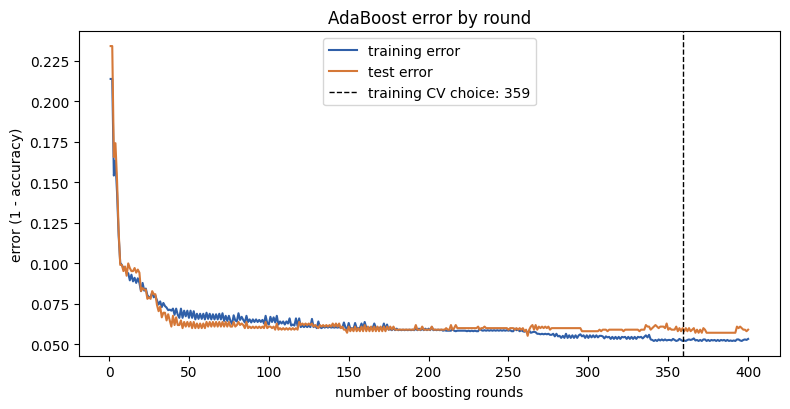

In [26]:
ada_train_error = 1 - np.asarray(list(ada.staged_score(X_train, y_train)))
ada_test_error = 1 - np.asarray(list(ada.staged_score(X_test, y_test)))
assert len(ada_train_error) == len(ada_test_error) == 400
test_best_round = int(np.argmin(ada_test_error)) + 1
chosen_test_error = ada_test_error[chosen_round - 1]
chosen_test_accuracy = 1 - chosen_test_error
chosen_test_se = np.sqrt(chosen_test_accuracy * (1 - chosen_test_accuracy) / len(y_test))
error_gap = chosen_test_error - ada_test_error[test_best_round - 1]

print(f"CV-selected round {chosen_round}: test error {chosen_test_error:.6f}")
print(f"lowest test error: {ada_test_error[test_best_round - 1]:.6f}, first at round {test_best_round}")
print(f"test error gap: {error_gap:.6f}; SE at chosen round: {chosen_test_se:.6f}")
print("gap exceeds one test SE:", error_gap > chosen_test_se)

rounds = np.arange(1, 401)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(rounds, ada_train_error, color="#2f5fa8", label="training error")
ax.plot(rounds, ada_test_error, color="#d57838", label="test error")
ax.axvline(chosen_round, color="black", linestyle="--", linewidth=1,
           label=f"training CV choice: {chosen_round}")
ax.set(xlabel="number of boosting rounds", ylabel="error (1 - accuracy)",
       title="AdaBoost error by round")
ax.legend()
plt.tight_layout()
plt.show()

For the noise experiment, only training labels change. Every model sees the same flipped rows in a draw, so losses can be paired by draw. The separate 200-round booster is fixed by the task and does not use the round selected above.

In [27]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx

ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}
clean_accuracy = {
    name: clone(model).fit(X_train, y_train).score(X_test, y_test)
    for name, model in noise_models.items()
}
noisy_accuracy = {name: [] for name in noise_models}
weight_rows = []
original_labels = y_train.copy()

for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)
    assert len(np.unique(idx)) == len(idx) == round(0.20 * len(y_train))
    assert np.array_equal(np.flatnonzero(y_noisy != y_train), np.sort(idx))
    for name, model in noise_models.items():
        noisy_model = clone(model).fit(X_train, y_noisy)
        noisy_accuracy[name].append(noisy_model.score(X_test, y_test))
        if name == "ada200":
            w = np.full(len(y_train), 1 / len(y_train))
            for stump in noisy_model.estimators_:
                _, w = adaboost_step(y_noisy, stump.predict(X_train), w)
            assert np.isclose(w.sum(), 1) and np.isfinite(w).all()
            weight_rows.append({"draw": r, "seed": SEED + r,
                                "initial flipped weight share": len(idx) / len(y_train),
                                "final flipped weight share": w[idx].sum()})
    print(f"noise draw {r} completed")

assert np.array_equal(y_train, original_labels)
noisy_accuracy = {name: np.asarray(values) for name, values in noisy_accuracy.items()}
noise_losses = {name: clean_accuracy[name] - noisy_accuracy[name] for name in noise_models}
noise_table = pd.DataFrame([{
    "model": name, "clean accuracy": clean_accuracy[name],
    "20% accuracy mean": noisy_accuracy[name].mean(), "20% accuracy std": noisy_accuracy[name].std(),
    "loss mean": noise_losses[name].mean(), "loss std": noise_losses[name].std(),
} for name in noise_models])
display(noise_table.round(4))

loss_table = score_table(noise_losses)
loss_table.columns = ["draw 0", "draw 1", "draw 2", "draw 3", "draw 4", "mean", "std"]
print("Loss = clean accuracy - noisy accuracy:")
display(loss_table.round(4))

noise_differences = {
    f"{left} loss - {right} loss": noise_losses[left] - noise_losses[right]
    for left, right in combinations(noise_models, 2)
}
noise_difference_table = score_table(noise_differences)
noise_difference_table.columns = loss_table.columns
print("Paired loss differences (positive means the first model loses more):")
display(noise_difference_table.round(4))

weight_table = pd.DataFrame(weight_rows)
display(weight_table.round(6))
final_weight_shares = weight_table["final flipped weight share"].to_numpy()
print(f"initial flipped weight share: {weight_table['initial flipped weight share'].iloc[0]:.6f}")
print(f"final flipped weight share: {final_weight_shares.mean():.6f} +/- {final_weight_shares.std():.6f}")

noise draw 0 completed


noise draw 1 completed


noise draw 2 completed


noise draw 3 completed


noise draw 4 completed


,model,clean accuracy,20% accuracy mean,20% accuracy std,loss mean,loss std
0,tree,0.9106,0.7382,0.0147,0.1724,0.0147
1,rf,0.9572,0.9047,0.0103,0.0525,0.0103
2,ada200,0.9410,0.9092,0.0074,0.0318,0.0074


... (2 outputs left out)

Paired loss differences (positive means the first model loses more):


,draw 0,draw 1,draw 2,draw 3,draw 4,mean,std
tree loss - rf loss,0.1123,0.1237,0.1427,0.1361,0.0847,0.1199,0.0205
tree loss - ada200 loss,0.1294,0.1494,0.1551,0.1408,0.1284,0.1406,0.0106
rf loss - ada200 loss,0.0171,0.0257,0.0124,0.0048,0.0438,0.0207,0.0134


,draw,seed,initial flipped weight share,final flipped weight share
0,0,2175,0.200127,0.398959
1,1,2176,0.200127,0.387488
2,2,2177,0.200127,0.395828
3,3,2178,0.200127,0.389223
4,4,2179,0.200127,0.391131


initial flipped weight share: 0.200127
final flipped weight share: 0.392526 +/- 0.004255


The three toy rounds give epsilon/alpha pairs of 0.300000/0.847298, 0.214286/1.299283 and 0.181818/1.504077. In round 1, correct rows have weight 0.071429 and wrong rows 0.166667, matching the handout's lecture check. On the real data, my first five updates match scikit-learn to floating-point rounding: the largest epsilon gap is about 1.11e-16 and the largest alpha gap about 5.55e-16.

Training CV selects round 359, with mean validation accuracy 0.939422. Its test error is 0.059943; the test curve first reaches its minimum of 0.055186 at round 262. The error gap, 0.004757, is smaller than the chosen round's test SE of 0.007322. I keep the training-selected round instead of tuning to the test minimum. Training error keeps falling overall, but the test curve does not improve in the same way.

With 20% training-label noise, the tree loses 0.1724 accuracy on average (std 0.0147), the forest loses 0.0525 (std 0.0103), and ada200 loses 0.0318 (std 0.0074). The paired loss differences are tree minus forest 0.1199 with std 0.0205, tree minus ada200 0.1406 with std 0.0106, and forest minus ada200 0.0207 with std 0.0134. All three mean differences exceed their paired std, so the loss ordering is outside the draw spread: the tree loses most, then the forest, then ada200. This ordering describes damage relative to each model's own clean baseline.

The deep tree can fit incorrect training labels, which damages its test predictions. Averaging reduces that problem for the forest. AdaBoost does focus on the noisy rows: their weight share grows from 0.200127 to 0.392526 on average, with std 0.004255. However, its weak learners are stumps and this experiment stops at 200 rounds; those limits help explain why it loses less accuracy here despite that extra attention to noise. These five draws support the result on this split, rather than a general claim that boosting is always robust to wrong labels.